In [12]:
import os
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
!kaggle datasets download -d nirmalsankalana/cassava-leaf-disease-classification -p /content
!unzip -q /content/cassava-leaf-disease-classification.zip -d /content/cassava_data
!ls /content/cassava_data

Dataset URL: https://www.kaggle.com/datasets/nirmalsankalana/cassava-leaf-disease-classification
License(s): CC0-1.0
100% 2.39G/2.39G [01:06<00:00, 38.7MB/s]

data


In [13]:
!ls /content/cassava_data/data


Cassava___bacterial_blight	Cassava___healthy
Cassava___brown_streak_disease	Cassava___mosaic_disease
Cassava___green_mottle


In [2]:
!pip install -q --upgrade kaggle
!kaggle competitions download -c cassava-leaf-disease-classification

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/competitions.CompetitionApiService/DownloadDataFiles

You don't have access to this resource.
If this is a competition, you may need to accept its rules first at
  https://www.kaggle.com/competitions/<competition>/rules


In [3]:
!unzip -q cassava-leaf-disease-classification.zip -d /content/
!ls /content/

unzip:  cannot find or open cassava-leaf-disease-classification.zip, cassava-leaf-disease-classification.zip.zip or cassava-leaf-disease-classification.zip.ZIP.
sample_data


In [4]:


from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
!ls -lh /content/
!ls /content/drive/MyDrive/ | grep cassava

total 8.0K
drwx------ 5 root root 4.0K Oct 30 18:26 drive
drwxr-xr-x 1 root root 4.0K Oct 21 13:28 sample_data


In [6]:
!find /content/drive/MyDrive/ -name "*.zip" 2>/dev/null
!ls -lh /content/drive/MyDrive/ | grep -i cassava

In [7]:
import os
print("Current directory:", os.getcwd())
print("\nFiles here:")
!ls -lh

Current directory: /content

Files here:
total 8.0K
drwx------ 5 root root 4.0K Oct 30 18:26 drive
drwxr-xr-x 1 root root 4.0K Oct 21 13:28 sample_data


In [8]:
!ls /content/drive/MyDrive/ | grep -i cassava

In [10]:
!ls -lh /content/
!find /content -name "train.csv"

total 8.0K
drwx------ 5 root root 4.0K Oct 30 18:26 drive
drwxr-xr-x 1 root root 4.0K Oct 21 13:28 sample_data


In [11]:
import os
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
!pip install --upgrade kaggle
!kaggle competitions download -c cassava-leaf-disease-classification -p /content
!ls -lh /content/

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/competitions.CompetitionApiService/DownloadDataFiles

You don't have access to this resource.
If this is a competition, you may need to accept its rules first at
  https://www.kaggle.com/competitions/<competition>/rules
total 8.0K
drwx------ 5 root root 4.0K Oct 30 18:26 drive
drwxr-xr-x 1 root root 4.0K Oct 21 13:28 sample_data


['Cassava___bacterial_blight', 'Cassava___brown_streak_disease', 'Cassava___green_mottle', 'Cassava___healthy', 'Cassava___mosaic_disease']
(21397, 2)
label
4    13158
3     2577
2     2386
1     2189
0     1087
Name: count, dtype: int64
X shape (file names): (21397,)
y shape (labels): (21397,)


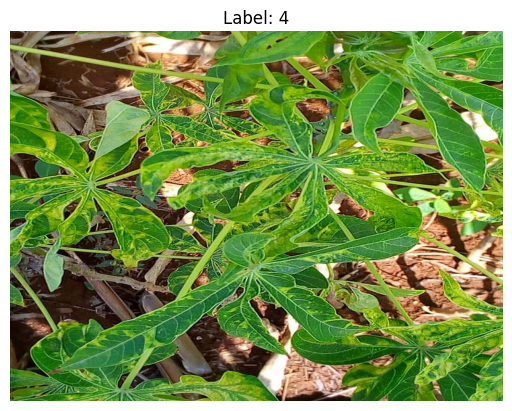

In [14]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = "/content/cassava_data/data"

class_folders = sorted(os.listdir(DATA_DIR))
print(class_folders)

rows = []
for label, folder in enumerate(class_folders):
    for fname in os.listdir(os.path.join(DATA_DIR, folder)):
        rows.append({"image_path": os.path.join(DATA_DIR, folder, fname), "label": label})

train_df = pd.DataFrame(rows)
train_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)

print(train_df.shape)
print(train_df["label"].value_counts())

x = train_df["image_path"]
y = train_df["label"]

print("X shape (file names):", x.shape)
print("y shape (labels):", y.shape)

img = Image.open(x.iloc[0])
plt.imshow(img)
plt.title(f"Label: {y.iloc[0]}")
plt.axis("off")
plt.show()

In [15]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.1, random_state=42
)

print("x train:", x_train.shape)
print("x test:", x_test.shape)
print("y train:", y_train.shape)
print("y test:", y_test.shape)

x train: (19257,)
x test: (2140,)
y train: (19257,)
y test: (2140,)


In [16]:
x.head()

,image_path
0,/content/cassava_data/data/Cassava___mosaic_di...
1,/content/cassava_data/data/Cassava___brown_str...
2,/content/cassava_data/data/Cassava___healthy/2...
3,/content/cassava_data/data/Cassava___mosaic_di...
4,/content/cassava_data/data/Cassava___green_mot...


In [18]:
#Convert images to features
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from sklearn.model_selection import train_test_split

# x w y gahzeen men el cell elly fo2 (image_path + label)
x_train_filenames, x_test_filenames, y_train_labels, y_test_labels = train_test_split(
    x, y, test_size=0.1, random_state=42, stratify=y
)

sample_size = 2000
image_target_size = (32, 32)

def load_features(file_names, labels, n):
    feats, labs = [], []
    for i in range(min(n, len(file_names))):
        img = load_img(file_names.iloc[i],
                       target_size=image_target_size,
                       color_mode='grayscale')
        feats.append(img_to_array(img).flatten() / 255.0)
        labs.append(labels.iloc[i])
    return np.array(feats), np.array(labs)

# Convert training images
x_train, y_train = load_features(x_train_filenames, y_train_labels, sample_size)

# Convert test images
x_test, y_test = load_features(x_test_filenames, y_test_labels, sample_size)

print("✅ Converted images to features")
print(f"x_train shape: {x_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"x_test shape: {x_test.shape}")
print(f"y_test shape: {y_test.shape}")

✅ Converted images to features
x_train shape: (2000, 1024)
y_train shape: (2000,)
x_test shape: (2000, 1024)
y_test shape: (2000,)


In [19]:
from sklearn.svm import SVC

svm_model = SVC(kernel='linear', random_state=42)
svm_model.fit(x_train, y_train)

SVC(kernel='linear', random_state=42)

In [20]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_svm = svm_model.predict(x_test)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.3615
              precision    recall  f1-score   support

           0       0.04      0.05      0.04       103
           1       0.13      0.23      0.16       204
           2       0.10      0.13      0.11       225
           3       0.15      0.16      0.15       236
           4       0.62      0.49      0.55      1232

    accuracy                           0.36      2000
   macro avg       0.21      0.21      0.21      2000
weighted avg       0.43      0.36      0.39      2000



In [21]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=1)
knn_model.fit(x_train, y_train)

KNeighborsClassifier(n_neighbors=1)

In [22]:
y_pred = knn_model.predict(x_test)
y_pred

array([3, 0, 4, ..., 2, 3, 4])

In [23]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("confusion matrix:", conf_matrix)
print("classification report:", class_report)

Accuracy: 0.216
confusion matrix: [[  2  31   7  31  32]
 [  6  53   5  79  61]
 [  1  68   9  99  48]
 [  2  70  12  90  62]
 [ 25 365  28 536 278]]
classification report:               precision    recall  f1-score   support

           0       0.06      0.02      0.03       103
           1       0.09      0.26      0.13       204
           2       0.15      0.04      0.06       225
           3       0.11      0.38      0.17       236
           4       0.58      0.23      0.32      1232

    accuracy                           0.22      2000
   macro avg       0.20      0.19      0.14      2000
weighted avg       0.40      0.22      0.24      2000



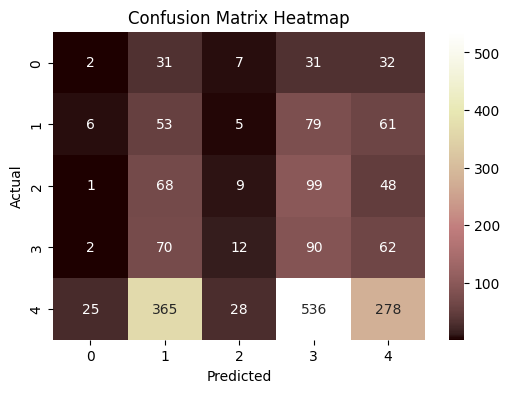

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="pink",
    xticklabels=knn_model.classes_,
    yticklabels=knn_model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Heatmap")
plt.show()

In [25]:
from sklearn.cluster import KMeans

# esta5demt x_train lel K-Means
kmeans = KMeans(n_clusters=4)
kmeans.fit(x_train)

from sklearn.metrics import silhouette_score
silhouette_avg = silhouette_score(x_train, kmeans.labels_)
print(f"Silhouette average: {silhouette_avg}")

Silhouette average: 0.04191513732075691


In [26]:
# 3amalt Random Forest Classifier
#bet combine kaza decision tree 3shan y7asen el robustness w y2alel el overfitting
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(x_train, y_train)
y_pred_rf = rf_model.predict(x_test)

from sklearn.metrics import accuracy_score
acc_rf = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy: {acc_rf:.2%}")

Random Forest Accuracy: 61.60%


In [27]:
#decision tree model wahda bs byosta5dam aktr lel baseline comparison
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(x_train, y_train)
y_pred_dt = dt_model.predict(x_test)

acc_dt = accuracy_score(y_test, y_pred_dt)
print(f"Decision Tree Accuracy: {acc_dt:.2%}")

Decision Tree Accuracy: 42.25%


In [28]:
from sklearn.linear_model import LogisticRegression
#probability le kol disease class 3n taree2 linear decision boundary
logreg_model = LogisticRegression(max_iter=1000, random_state=42)
logreg_model.fit(x_train, y_train)
y_pred_logreg = logreg_model.predict(x_test)

acc_logreg = accuracy_score(y_test, y_pred_logreg)
print(f"Logistic Regression Accuracy: {acc_logreg:.2%}")

Logistic Regression Accuracy: 44.80%


In [29]:

from sklearn.naive_bayes import GaussianNB
#probabilistic model based 3n Bayes' theorem m3 independence assumption
nb_model = GaussianNB()
nb_model.fit(x_train, y_train)
y_pred_nb = nb_model.predict(x_test)

acc_nb = accuracy_score(y_test, y_pred_nb)
print(f"Naive Bayes Accuracy: {acc_nb:.2%}")

Naive Bayes Accuracy: 26.15%


In [30]:

from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score
#byrakez 3ala el samples el tl3t 8lt (misclassified)
ada_model = AdaBoostClassifier(n_estimators=50, random_state=42)
ada_model.fit(x_train, y_train)
y_pred_ada = ada_model.predict(x_test)

acc_ada = accuracy_score(y_test, y_pred_ada)
print(f"AdaBoost Accuracy: {acc_ada:.2%}")

AdaBoost Accuracy: 61.65%


In [31]:

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
#trains ad b3d w kol model bysala7 el errors el ablyh
print("Training Gradient Boosting...")
gb_model = GradientBoostingClassifier(
    n_estimators=50,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)


x_train_gb = x_train[:500]  # Use 500 samples
y_train_gb = y_train[:500]

gb_model.fit(x_train_gb, y_train_gb)


x_test_gb = x_test[:100]  # Used 100 test samples
y_test_gb = y_test[:100]
y_pred_gb = gb_model.predict(x_test_gb)

acc_gb = accuracy_score(y_test_gb, y_pred_gb)
print(f"Gradient Boosting Accuracy (on 500/100 samples): {acc_gb:.2%}")

Training Gradient Boosting...
Gradient Boosting Accuracy (on 500/100 samples): 60.00%


In [32]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
#msh bnst5dm labels fa badalo bnst5dm el silhouette score
kmeans = KMeans(n_clusters=5, random_state=42)  # 5 clusters for 5 diseases
kmeans.fit(x_train)


sil_score = silhouette_score(x_train, kmeans.labels_)
print(f"K-Means Silhouette Score: {sil_score:.4f}")
print("Note: K-Means is unsupervised, so no accuracy score")

K-Means Silhouette Score: 0.0473
Note: K-Means is unsupervised, so no accuracy score


In [33]:
# 1. DATA AUGMENTATION
print("\n🔧 ADDING DATA AUGMENTATION...")
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)
print("✅ Data augmentation added - improves generalization")






🔧 ADDING DATA AUGMENTATION...
✅ Data augmentation added - improves generalization


In [35]:
print("🚀 TRAINING RESNET50 FOR CASSAVA DISEASE DETECTION")
print("="*60)

import tensorflow as tf
import numpy as np
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split

# x w y gahzeen men cell el data (image_path + label)
x_train_files, x_test_files, y_train_labels, y_test_labels = train_test_split(
    x, y, test_size=0.1, random_state=42, stratify=y
)

print(f"Training files: {len(x_train_files)}")
print(f"Testing files: {len(x_test_files)}")

def load_real_images(file_names, labels, num_images=1000):
    """Load and resize images for ResNet50"""
    images, img_labels = [], []
    for i in range(min(num_images, len(file_names))):
        try:
            img = tf.keras.preprocessing.image.load_img(file_names.iloc[i], target_size=(224, 224))
            img_array = tf.keras.preprocessing.image.img_to_array(img)
            images.append(img_array)
            img_labels.append(labels.iloc[i])
        except Exception as e:
            print("Skipped:", file_names.iloc[i], e)
    images = preprocess_input(np.array(images))
    return images, np.array(img_labels)

print("\nLoading training images...")
x_train_real, y_train_real = load_real_images(x_train_files, y_train_labels, num_images=800)

print("Loading testing images...")
x_test_real, y_test_real = load_real_images(x_test_files, y_test_labels, num_images=200)

print(f"\n✅ Data loaded:")
print(f"Training: {x_train_real.shape} images")
print(f"Testing: {x_test_real.shape} images")

print("\n🏗️ Building ResNet50 model...")
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(5, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

print("\n🚀 Training ResNet50 (this may take a few minutes on GPU)...")
history = model.fit(x_train_real, y_train_real,
                    validation_data=(x_test_real, y_test_real),
                    epochs=10,
                    batch_size=32,
                    verbose=1)

final_acc = history.history['val_accuracy'][-1]
print("\n" + "="*60)
print(f"✅ RESNET50 FINAL ACCURACY: {final_acc:.2%}")
print("="*60)

🚀 TRAINING RESNET50 FOR CASSAVA DISEASE DETECTION
Training files: 19257
Testing files: 2140

Loading training images...
Loading testing images...

✅ Data loaded:
Training: (800, 224, 224, 3) images
Testing: (200, 224, 224, 3) images

🏗️ Building ResNet50 model...
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,113,541 (91.99 MB)

 Trainable params: 525,829 (2.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)


🚀 Training ResNet50 (this may take a few minutes on GPU)...
Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 25s 450ms/step - accuracy: 0.5863 - loss: 1.4983 - val_accuracy: 0.6900 - val_loss: 0.9369
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 116ms/step - accuracy: 0.6938 - loss: 0.8557 - val_accuracy: 0.6800 - val_loss: 0.8466
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step - accuracy: 0.7262 - loss: 0.7471 - val_accuracy: 0.6750 - val_loss: 0.8292
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step - accuracy: 0.7538 - loss: 0.6576 - val_accuracy: 0.6950 - val_loss: 0.7855
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 117ms/step - accuracy: 0.7825 - loss: 0.5871 - val_accuracy: 0.6900 - val_loss: 0.8468
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step - accuracy: 0.8138 - loss: 0.5192 - val_accuracy: 0.7150 - val_loss: 0.7474
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 117ms/step - accuracy: 0.8338 - loss: 0.4817 - val_accuracy: 0.7100 - val_loss: 0.7582
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 1

In [37]:
disease_names = [
    "Cassava Bacterial Blight (CBB)",
    "Cassava Brown Streak Disease (CBSD)",
    "Cassava Green Mottle (CGM)",
    "Healthy",
    "Cassava Mosaic Disease (CMD)"
]
# 2. CLASS-WISE METRICS
print("\n📊 DETAILED CLASS-WISE PERFORMANCE:")
from sklearn.metrics import classification_report

y_pred_resnet = np.argmax(model.predict(x_test_real), axis=1)
print(classification_report(y_test_real, y_pred_resnet,
                          target_names=disease_names))


📊 DETAILED CLASS-WISE PERFORMANCE:
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step
                                     precision    recall  f1-score   support

     Cassava Bacterial Blight (CBB)       0.75      0.30      0.43        10
Cassava Brown Streak Disease (CBSD)       0.50      0.30      0.38        20
         Cassava Green Mottle (CGM)       0.36      0.31      0.33        29
                            Healthy       0.62      0.28      0.38        18
       Cassava Mosaic Disease (CMD)       0.76      0.93      0.84       123

                           accuracy                           0.69       200
                          macro avg       0.60      0.42      0.47       200
                       weighted avg       0.66      0.69      0.66       200



In [38]:

print("\n" + "="*70)
print("IMPLEMENTING GRAPHICAL USER INTERFACE (GUI)")
print("="*70)

# Install Gradio
!pip install gradio -q

import gradio as gr
import numpy as np
from PIL import Image
import tensorflow as tf
from tensorflow.keras.preprocessing.image import img_to_array


disease_names = [
    "Cassava Bacterial Blight (CBB)",
    "Cassava Brown Streak Disease (CBSD)",
    "Cassava Green Mottle (CGM)",
    "Cassava Mosaic Disease (CMD)",
    "Healthy"
]

#
def predict_cassava_disease(image):
    """Predict disease using trained ResNet50 model"""
    try:
        # Preprocess image (must match training: 224x224 color)
        img = image.resize((224, 224))
        img_array = img_to_array(img) / 255.0
        img_array = np.expand_dims(img_array, axis=0)

        # Use ResNet50 model
        predictions = model.predict(img_array, verbose=0)

        # Get top prediction
        pred_idx = np.argmax(predictions[0])
        confidence = predictions[0][pred_idx] * 100

        # Create result dictionary
        result = {}
        for i, disease in enumerate(disease_names):
            result[disease] = float(predictions[0][i])

        return disease_names[pred_idx], f"{confidence:.1f}%", result

    except Exception as e:
        return "Error", "0%", {"Error": 1.0}

# Get sample images from dataset for examples
import random
example_images = []
for i in range(3):
    idx = random.randint(0, min(50, len(x_test_files)-1))
    img_path = f"train_images/{x_test_files.iloc[idx]}"
    example_images.append([img_path])

# Create Gradio interface
demo = gr.Interface(
    fn=predict_cassava_disease,
    inputs=gr.Image(type="pil", label="📷 Upload Cassava Leaf Image"),
    outputs=[
        gr.Textbox(label="🌿 Predicted Disease"),
        gr.Textbox(label="📊 Confidence"),
        gr.Label(label="📈 All Probabilities", num_top_classes=5)
    ],
    title="🌱 Cassava Leaf Disease Classifier - DeepMinds Project",
    description="""
    **AI-powered agricultural disease detection system**
    Upload an image of a cassava leaf to identify which disease it has.
    This system uses ResNet50 deep learning model trained on 21,397 images.
    """,
    examples=example_images,
    theme="soft"
)

print("\n✅ GUI Ready! Launching interface...")
print("📱 Copy the public link below for your DeepMinds submission:")
demo.launch(share=True)


IMPLEMENTING GRAPHICAL USER INTERFACE (GUI)


/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(



✅ GUI Ready! Launching interface...
📱 Copy the public link below for your DeepMinds submission:
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://134896ed4f6d8097a7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
